In [39]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

In [40]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [41]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [42]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [43]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [44]:
Numerical_Col = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

In [45]:
Categorical_Col = ['lead_source','industry','employment_status','location']

In [46]:
df[Categorical_Col] = df[Categorical_Col].fillna('NA')

In [47]:
df[Numerical_Col] = df[Numerical_Col].fillna(0.0)

In [48]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [49]:
# Q 1 / 

Numerical_Col = ['annual_income','number_of_courses_viewed','interaction_count','lead_score']

auc_scores = {}

for feature in Numerical_Col:
    auc = roc_auc_score(df_train['converted'], df_train[feature])
    
    if auc < 0.5:
        auc = roc_auc_score(df_train['converted'], -df_train[feature])
        
    auc_scores[feature] = auc
    print(f"AUC for {feature}: {auc:.4f}")


best_feature = max(auc_scores, key=auc_scores.get)
print(f"\n---> The numerical variable with the highest AUC is: '{best_feature}' ({auc_scores[best_feature]:.4f})")

AUC for annual_income: 0.6082
AUC for number_of_courses_viewed: 0.7230
AUC for interaction_count: 0.7649
AUC for lead_score: 0.7882

---> The numerical variable with the highest AUC is: 'lead_score' (0.7882)


In [50]:
df.shape

(5000, 9)

In [51]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [52]:
y_train = df_train['converted']
y_val = df_val['converted']
y_test = df_test['converted']

In [53]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [54]:
df_train_dict = df_train[Numerical_Col + Categorical_Col ].to_dict(orient='records')

In [55]:
df_val_dict = df_val[Numerical_Col + Categorical_Col ].to_dict(orient='records')

In [56]:
dv = DictVectorizer(sparse=False)

In [57]:
X_train = dv.fit_transform(df_train_dict)

In [58]:
X_val = dv.transform(df_val_dict)

In [59]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [60]:
model.fit(X_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [61]:
y_pred = model.predict_proba(X_val)[:, 1]

In [62]:
converted_decision = (y_pred >= 0.5)

In [63]:
(y_val == converted_decision).mean()

np.float64(0.651)

In [64]:
y_val.shape , converted_decision.shape

((1000,), (1000,))

In [65]:
# Q 2 

y_pred = model.predict_proba(X_val)[:, 1]

auc_val = roc_auc_score(y_val, y_pred)

print("Validation AUC:", round(auc_val, 3))

Validation AUC: 0.732


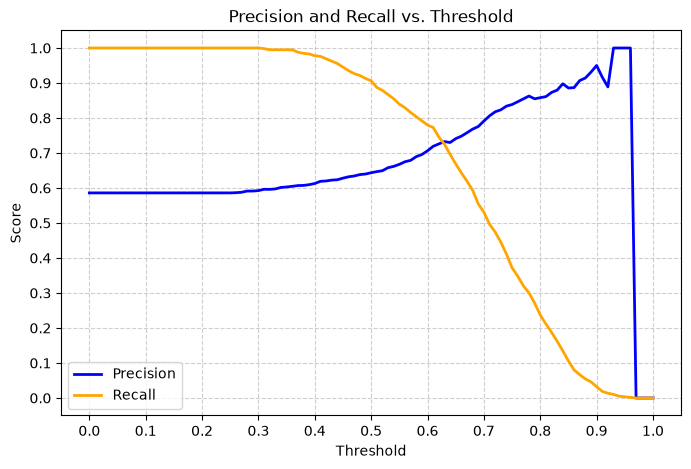

Intersection Threshold: 0.63
Precision: 0.7328, Recall: 0.7253


In [66]:
# Q 3 

y_pred = model.predict_proba(X_val)[:, 1]

thresholds = np.linspace(0.0, 1.0, 101)

precisions = []
recalls = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    precisions.append(p)
    recalls.append(r)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='orange', linewidth=2)
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Precision and Recall vs. Threshold')
plt.xticks(np.arange(0.0, 1.05, 0.1))
plt.yticks(np.arange(0.0, 1.05, 0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

min_diff = float('inf')
best_threshold = None
best_precision = None
best_recall = None

for t, p, r in zip(thresholds, precisions, recalls):
    if p == 0 and r == 0:
        continue
    
    diff = abs(p - r)
    if diff < min_diff:
        min_diff = diff
        best_threshold = t
        best_precision = p
        best_recall = r

print(f"Intersection Threshold: {best_threshold:.2f}")
print(f"Precision: {best_precision:.4f}, Recall: {best_recall:.4f}")

Maximal F1 score: 0.7576
---> F1 is maximal at threshold: 0.41


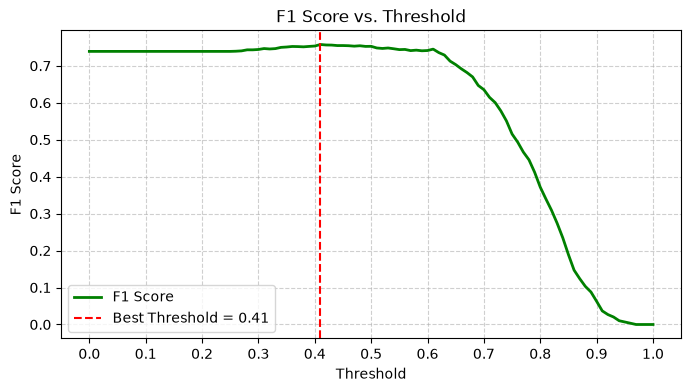

In [67]:
# Q 4 

thresholds = np.linspace(0.0, 1.0, 101)
f1_scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)
    
    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    
    f1 = 2 * (p * r) / (p + r) if (p + r) > 0 else 0.0
    f1_scores.append(f1)


f1_scores = np.array(f1_scores)
max_idx = np.argmax(f1_scores)
best_threshold = thresholds[max_idx]
max_f1 = f1_scores[max_idx]

print(f"Maximal F1 score: {max_f1:.4f}")
print(f"---> F1 is maximal at threshold: {best_threshold:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, color='green', linewidth=2, label='F1 Score')
plt.axvline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.ylabel('F1 Score')
plt.title('F1 Score vs. Threshold')
plt.xticks(np.arange(0.0, 1.05, 0.1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

In [68]:
# Q 5 

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    
    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values
    
    train_dict = df_train_fold[Numerical_Col + Categorical_Col].to_dict(orient='records')
    val_dict = df_val_fold[Numerical_Col + Categorical_Col].to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(train_dict)
    X_val_fold = dv.transform(val_dict)
    
    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X_train_fold, y_train_fold)
    
    y_pred = model.predict_proba(X_val_fold)[:, 1]
    
    auc = roc_auc_score(y_val_fold, y_pred)
    scores.append(auc)

mean_auc = np.mean(scores)
std_auc = np.std(scores)

print(f"AUC Scores for each fold: {[round(s, 4) for s in scores]}")
print(f"Mean AUC: {mean_auc:.3f}")
print(f"---> Standard Deviation (std): {std_auc:.3f}")

AUC Scores for each fold: [0.7306, 0.7296, 0.7363, 0.7412, 0.7209]
Mean AUC: 0.732
---> Standard Deviation (std): 0.007


In [69]:
# Q 6 

C_values = [0.000001, 0.001, 1]

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

print(f"{'C':<12} | {'Mean AUC':<10} | {'Std':<8}")
print("-" * 35)

results = {}

for c in C_values:
    scores = []
    
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        
        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values
        
        train_dict = df_train_fold[Numerical_Col + Categorical_Col].to_dict(orient='records')
        val_dict = df_val_fold[Numerical_Col + Categorical_Col].to_dict(orient='records')
        
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(train_dict)
        X_val_fold = dv.transform(val_dict)
        
        model = LogisticRegression(solver='liblinear', C=c, max_iter=1000)
        model.fit(X_train_fold, y_train_fold)
        
        y_pred = model.predict_proba(X_val_fold)[:, 1]
        auc = roc_auc_score(y_val_fold, y_pred)
        scores.append(auc)
        
    mean_score = round(np.mean(scores), 3)
    std_score = round(np.std(scores), 3)
    results[c] = (mean_score, std_score)
    
    print(f"{c:<12} | {mean_score:<10.3f} | {std_score:<8.3f}")

best_c = max(results, key=lambda k: results[k][0])
print(f"\n---> The C that leads to the best mean ROC AUC is: {best_c}")

C            | Mean AUC   | Std     
-----------------------------------
1e-06        | 0.617      | 0.019   
0.001        | 0.749      | 0.010   
1            | 0.732      | 0.007   

---> The C that leads to the best mean ROC AUC is: 0.001
